# Lab Sheet 4 – Fine-Tuning an Instruction-Tuned LLM using QLoRA


## 1. Install and import the required libraries

The practical uses Hugging Face Transformers and Datasets, PEFT for LoRA, TRL for supervised fine-tuning, Accelerate for device placement, and bitsandbytes for 4-bit quantization.

In [3]:
!pip install -q "pyarrow>=19,<24"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.2.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.


In [2]:
import os
import json
import random
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cu130


In [4]:
import pyarrow
import datasets
import transformers
import peft
import trl
import accelerate
import bitsandbytes
import torch

print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nAll required libraries imported successfully!")

PyArrow: 26.0.1
Datasets: 5.2.0
Transformers: 5.23.0
PEFT: 0.21.3
TRL: 1.18.1
Accelerate: 1.16.0
BitsAndBytes: 0.50.2
CUDA available: True
GPU: Tesla T4

All required libraries imported successfully!


## 2. Identify the GPU and available memory


In [5]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU is available. In Google Colab, select "
        "Runtime > Change runtime type > T4 GPU, then rerun the notebook."
    )

gpu = torch.cuda.get_device_properties(0)
total_memory_gib = gpu.total_memory / (1024 ** 3)

print("GPU:", gpu.name)
print(f"Total GPU memory: {total_memory_gib:.2f} GiB")
print("CUDA version:", torch.version.cuda)
print("Compute capability:", f"{gpu.major}.{gpu.minor}")

# T4 (compute capability 7.5) supports FP16 but not BF16.
USE_BF16 = gpu.major >= 8
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
print("Training precision:", "BF16" if USE_BF16 else "FP16")

GPU: Tesla T4
Total GPU memory: 14.56 GiB
CUDA version: 13.0
Compute capability: 7.5
Training precision: FP16


### Observation
- **Which GPU did Colab assign?**


    Google Colab assigned an NVIDIA Tesla T4 GPU to my session. It was used to accelerate the fine-tuning process.

- **How much GPU memory was available?**
      
    The Tesla T4 GPU provided approximately 14.56 GiB of GPU memory (VRAM). This memory is used to store model parameters, intermediate calculations, activations and other data required during training.
- **Which precision was selected (FP16 or BF16)?**

    FP16 (16-bit floating-point precision) was selected.
    The Tesla T4 has a compute capability of 7.5, which supports FP16 but does not provide native BF16 support. Therefore, FP16 was selected for the fine-tuning process.
- **Why is a GPU useful for fine-tuning a language model?**

    A GPU is useful because fine-tuning a language model involves many computationally intensive operations, particularly matrix multiplications and tensor calculations.
    GPUs can perform many of these operations in parallel, making model training faster than relying only on a CPU. They also provide dedicated high-bandwidth memory (VRAM) to store model parameters, activations and other training data.


## 3. Select a small instruction-tuned language model


In [6]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("Selected model:", MODEL_NAME)

Selected model: Qwen/Qwen2.5-0.5B-Instruct


### Observation

The Qwen2.5-0.5B-Instruct model was selected for this practical because it is a relatively small, instruction-tuned causal language model.

## 4. Create a domain-specific dataset (32 question-and-answer pairs)


In [7]:
SYSTEM_PROMPT = (
    "You are the customer-support assistant for TechNova Computers, a fictional "
    "computer shop in Colombo, Sri Lanka. Answer politely and concisely. "
    "Use only the business information provided in the conversation. "
    "Do not invent prices, stock availability, services, warranty terms, or policies. "
    "If the information is not provided, clearly say that you do not have that "
    "information and recommend contacting the shop. Do not guess."
)

qa_pairs = [
    ("What are your opening hours?", "We are open Monday to Saturday from 9:00 AM to 7:00 PM. We are closed on Sundays."),
    ("Are you open on Sundays?", "No. TechNova Computers is closed on Sundays."),
    ("Where is TechNova Computers located?", "We are located at 25 Galle Road, Colombo 03, Sri Lanka."),
    ("What is your contact phone number?", "You can contact TechNova Computers on 011 234 5678."),
    ("What is your email address?", "You can email us at support@technova.example."),
    ("Do you sell laptops?", "Yes. We sell laptops for study, office work, and general use. Please contact us for current models and stock."),
    ("Do you sell desktop computers?", "Yes. We sell desktop computers for home, office, and other general computing needs."),
    ("Can I order a custom-built PC?", "Yes. We can help customers plan a custom-built desktop PC based on their requirements and budget."),
    ("Do you provide laptop repairs?", "Yes. We provide laptop diagnosis and repair services."),
    ("Do you repair desktop computers?", "Yes. We provide desktop computer diagnosis and repair services."),
    ("Can you repair a broken phone screen?", "No. Phone screen repair is not a service offered by TechNova Computers."),
    ("Do new laptops have a warranty?", "Yes. New laptops purchased from us come with a 2-year manufacturer warranty."),
    ("What is the warranty for a new desktop computer?", "New desktop computers come with a 1-year TechNova shop warranty."),
    ("Can I return an unopened product?", "An unopened product can be returned within 7 days of purchase with the original receipt for a full refund."),
    ("Can I get a refund for an opened product if I changed my mind?", "Opened products are not eligible for a change-of-mind refund. If an item is faulty, contact us so we can explain the applicable warranty process."),
    ("What do I need to bring to return an item?", "For an eligible return, bring the unopened product and the original purchase receipt within 7 days of purchase."),
    ("Do you offer a student discount?", "Yes. Eligible students receive a 5% discount when they present a valid student ID."),
    ("How can I receive the student discount?", "Present a valid student ID when making your purchase to receive the 5% student discount on eligible products."),
    ("Do you deliver products?", "Yes. Delivery is available. Contact the shop to confirm the delivery fee and availability for your location."),
    ("Is delivery free?", "Delivery fees depend on the delivery location. Please contact us for the exact fee."),
    ("What payment methods do you accept?", "We accept cash, debit cards, and credit cards."),
    ("Can I pay by credit card?", "Yes. We accept credit card payments."),
    ("Do you offer instalment payments?", "Instalment availability and conditions may depend on the card issuer or payment provider. Please contact us to confirm current options."),
    ("Can I check whether a laptop is in stock?", "Yes. Contact us with the laptop model you are interested in, and our staff can check current stock."),
    ("Do you sell computer accessories?", "Yes. We sell computer accessories. Contact us to check the availability of a specific item."),
    ("Can you recommend a laptop for university?", "We can help you choose a laptop based on your course requirements and budget. Please share those details with our staff."),
    ("Do you provide technical support after purchase?", "Yes. Contact our support team for assistance with products purchased from TechNova Computers."),
    ("How long does a repair take?", "Repair time depends on the problem and parts availability. Our technicians can provide an estimate after diagnosis."),
    ("Can I get a repair cost before the repair starts?", "Our technicians can provide a repair estimate after diagnosing the device."),
    ("Do you sell used laptops?", "The availability of used laptops is not specified here. Please contact the shop to confirm whether any are available."),
    ("Can I reserve a product?", "Please contact the shop with the product model to ask whether a reservation can be arranged."),
    ("What should I do if my laptop battery drains quickly?", "We offer laptop diagnosis and repair. Bring the laptop in or contact our team so the battery issue can be assessed.")
]

assert len(qa_pairs) >= 30, "The assignment requires at least 30 Q&A pairs."
assert len(qa_pairs) == 32
print("Number of Q&A pairs:", len(qa_pairs))
print("Example:", qa_pairs[0])

Number of Q&A pairs: 32
Example: ('What are your opening hours?', 'We are open Monday to Saturday from 9:00 AM to 7:00 PM. We are closed on Sundays.')


### Observation
Created 32 question-and-answer pairs covering TechNova Computers' products, services, store policies, and customer support. The dataset was divided into 25 training examples and 7 evaluation examples to train and test the model.

### 4.1 Convert the Q&A pairs into a conversational Hugging Face dataset

Each example contains a system message, a user question, and the expected assistant response. The dataset is split into training and evaluation portions using a fixed random seed. The evaluation portion is not used to update model weights.

In [8]:
records = []
for question, answer in qa_pairs:
    records.append({
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": question},
            {"role": "assistant", "content": answer},
        ]
    })

full_dataset = Dataset.from_list(records)
split_dataset = full_dataset.train_test_split(test_size=0.20, seed=SEED)
train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

print("Full dataset:", len(full_dataset))
print("Training examples:", len(train_dataset))
print("Evaluation examples:", len(eval_dataset))
print("\nExample training record:")
print(train_dataset[0]["messages"])

Full dataset: 32
Training examples: 25
Evaluation examples: 7

Example training record:
[{'role': 'system', 'content': 'You are the customer-support assistant for TechNova Computers, a fictional computer shop in Colombo, Sri Lanka. Answer politely and concisely. Use only the business information provided in the conversation. Do not invent prices, stock availability, services, warranty terms, or policies. If the information is not provided, clearly say that you do not have that information and recommend contacting the shop. Do not guess.'}, {'role': 'user', 'content': 'Do you offer instalment payments?'}, {'role': 'assistant', 'content': 'Instalment availability and conditions may depend on the card issuer or payment provider. Please contact us to confirm current options.'}]


### 4.2 Save the dataset as JSON Lines


In [9]:
with open("technova_qa.jsonl", "w", encoding="utf-8") as f:
    for row in records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Saved: technova_qa.jsonl")

Saved: technova_qa.jsonl


## 5. Load the model in 4-bit precision (QLoRA)


In [10]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
)
model.config.use_cache = False

print("Model loaded successfully.")
print("Model class:", model.__class__.__name__)
print("Tokenizer padding token:", tokenizer.pad_token)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.
Model class: Qwen2ForCausalLM
Tokenizer padding token: <|endoftext|>


### Observation


**1. What does 4-bit quantization do?**

It stores model weights using 4 bits instead of higher precision, reducing GPU memory usage.

**2. Why are NF4 and double quantization used?**

NF4 efficiently represents model weights, while double quantization further reduces memory usage by compressing scaling constants.

**3. Why is this useful on a GPU with limited VRAM?**

It reduces the memory occupied by the base model, leaving more VRAM available for training.

**Observation from execution:**

The Qwen2.5-0.5B-Instruct model was successfully loaded using 4-bit NF4 quantization with double quantization enabled, preparing it for fine-tuning on the Tesla T4 GPU.


## 6. Record original-model answers before fine-tuning


In [11]:
def generate_answer(model_to_use, tokenizer_to_use, question, max_new_tokens=120):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]

    prompt = tokenizer_to_use.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer_to_use(prompt, return_tensors="pt").to(model_to_use.device)

    with torch.no_grad():
        output_ids = model_to_use.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer_to_use.eos_token_id,
            eos_token_id=tokenizer_to_use.eos_token_id,
        )

    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer_to_use.decode(new_tokens, skip_special_tokens=True).strip()


# Include questions whose answers are represented in training and questions
# that were deliberately not included in the 32 training examples.
test_questions = [
    {"question": "What time do you close on Saturday?", "category": "Seen fact / paraphrase"},
    {"question": "I am a university student. What discount can I get?", "category": "Seen fact / paraphrase"},
    {"question": "I bought an unopened item five days ago. Can I return it?", "category": "Seen fact / application"},
    {"question": "Is the shop open tomorrow if tomorrow is Sunday?", "category": "Unseen question"},
    {"question": "My new laptop has a problem. How long is its warranty?", "category": "Unseen question"},
    {"question": "Can I pay using a debit card?", "category": "Unseen question"},
    {"question": "Can you replace the screen of my smartphone?", "category": "Unseen / service boundary"},
    {"question": "Do you know the current price of a 16 GB RAM laptop?", "category": "Unseen / unknown information"},
    {"question": "What is the capital of France?", "category": "Out-of-domain"},
]

base_answers = []
for item in test_questions:
    base_answers.append(
        generate_answer(model, tokenizer, item["question"])
    )

print("Original-model responses recorded:", len(base_answers))

Original-model responses recorded: 9


### Observation

The original Qwen2.5-0.5B-Instruct model was tested with nine customer-support questions. It generated general answers but lacked knowledge of TechNova's specific policies.

For example, it incorrectly stated a 20% student discount and a 30-day return period instead of the actual 5% discount and seven-day return policy. This showed the need for fine-tuning to adapt the model to TechNova's information.

## 7. Configure LoRA adapters

LoRA freezes the original model weights and learns a smaller set of additional adapter weights. The attention and feed-forward projection layers used below are common LoRA targets for Qwen-style transformer models.

In [12]:
model = prepare_model_for_kbit_training(model)

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
)

print("LoRA configuration:")
print(peft_config)

LoRA configuration:
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.3', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'gate_proj', 'q_proj', 'k_proj', 'v_proj', 'down_proj', 'up_proj', 'o_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=No

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


### Observation
LoRA is parameter-efficient because it freezes the original base model weights and trains only the additional adapter parameters. This reduces the number of parameters that need to be updated during fine-tuning.

In this experiment, the LoRA configuration was successfully applied to the quantized Qwen model.


## 8. Fine-tune using the TRL SFTTrainer

The training configuration uses a small batch size, gradient accumulation, a learning rate suitable for LoRA experiments, and evaluation at the end of each epoch. Training and evaluation datasets are kept separate.

In [14]:

output_dir = "technova-qlora-results"

sft_config = SFTConfig(
    output_dir=output_dir,
    num_train_epochs=6,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=2,
    optim="paged_adamw_8bit",
    logging_steps=1,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=not USE_BF16,
    bf16=USE_BF16,
    max_length=512,
    report_to="none",
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)

trainable_params = sum(
    p.numel() for p in trainer.model.parameters() if p.requires_grad
)
total_params = sum(
    p.numel() for p in trainer.model.parameters()
)
trainable_percent = 100 * trainable_params / total_params

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {trainable_percent:.4f}%")


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/25 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/7 [00:00<?, ? examples/s]

Trainable parameters: 8,798,208
Total parameters: 323,917,696
Trainable percentage: 2.7162%


In [20]:

# Convert trainable LoRA parameters to FP32
for name, param in trainer.model.named_parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

# Verify the trainable parameter dtypes
from collections import Counter

dtype_counts = Counter(
    str(p.dtype)
    for p in trainer.model.parameters()
    if p.requires_grad
)

print("Trainable parameter dtypes:", dtype_counts)


Trainable parameter dtypes: Counter({'torch.float32': 336})


### Run training

In [22]:
train_result = trainer.train()

train_metrics = train_result.metrics

print("Training metrics:")
for key, value in train_metrics.items():
    print(f"{key}: {value}")

Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,1.803923,1.490056,2.094753,0.690953,3546.000000
2,0.563446,0.556173,0.554202,0.870701,6580.000000
3,0.233612,0.533632,0.340173,0.874864,9614.000000
4,0.329494,0.577984,0.255887,0.882878,12648.000000
5,0.052204,0.614203,0.241333,0.879853,15682.000000
6,0.091170,0.641432,0.232429,0.878866,18716.000000


Training metrics:
train_runtime: 52.1342
train_samples_per_second: 2.877
train_steps_per_second: 0.806
total_flos: 42417230119680.0
train_loss: 0.750512412882277
epoch: 6.0


### Evaluate on the held-out evaluation split

In [23]:
eval_metrics = trainer.evaluate()
print("Evaluation metrics:")
for key, value in eval_metrics.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Entropy,Mean Token Accuracy,Num Tokens
0.091170,0.641432,6,0.232429,0.878866,18716.000000


Evaluation metrics:
eval_loss: 0.641431987285614
eval_entropy: 0.23242923989892006
eval_mean_token_accuracy: 0.878865659236908
eval_num_tokens: 18716.0


### Plot training loss

The chart uses the training-loss values logged by the Trainer. If evaluation loss is available, it is plotted separately.

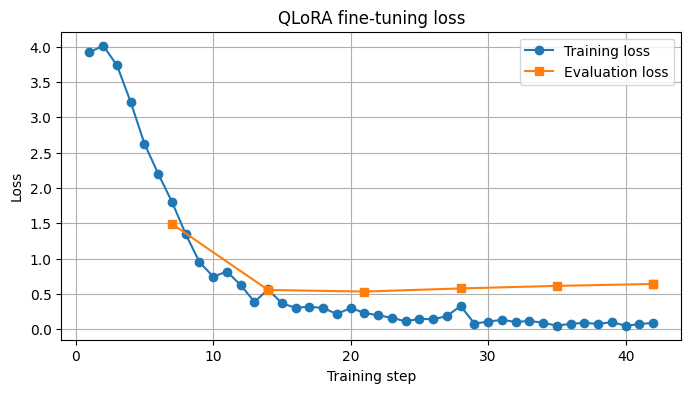

In [24]:
history = pd.DataFrame(trainer.state.log_history)

if "loss" in history.columns:
    train_log = history.dropna(subset=["loss"])
    plt.figure(figsize=(8, 4))
    plt.plot(train_log["step"], train_log["loss"], marker="o", label="Training loss")
    if "eval_loss" in history.columns:
        eval_log = history.dropna(subset=["eval_loss"])
        if not eval_log.empty:
            plt.plot(eval_log["step"], eval_log["eval_loss"], marker="s", label="Evaluation loss")
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title("QLoRA fine-tuning loss")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No training-loss values were found in the Trainer log history.")

### Observation 7

**1. Trainable parameters:**  
8,798,208 out of 323,917,696 parameters were trainable (2.7162%), demonstrating the efficiency of LoRA.

**2. Training loss:**  
Training loss generally decreased from 1.8039 to 0.0912 over six epochs, showing that the model learned from the training data.

**3. Final evaluation loss:**  
The final evaluation loss was 0.6414.

**4. Evaluation loss trend:**  
Evaluation loss decreased initially to 0.5562 in epoch 2, but increased to 0.6414 by epoch 6, suggesting possible overfitting.

**5. Overall observation:**  
The model learned the training examples, but the small dataset (25 training and 7 evaluation examples) may have limited its ability to generalise.




## 9. Compare the original and fine-tuned models

In [25]:
fine_tuned_model = trainer.model
fine_tuned_model.eval()

fine_tuned_answers = []
for item in test_questions:
    fine_tuned_answers.append(
        generate_answer(fine_tuned_model, tokenizer, item["question"])
    )

comparison_df = pd.DataFrame({
    "Category": [x["category"] for x in test_questions],
    "Question": [x["question"] for x in test_questions],
    "Original model": base_answers,
    "Fine-tuned model": fine_tuned_answers,
})

pd.set_option("display.max_colwidth", 250)
display(comparison_df)

,Category,Question,Original model,Fine-tuned model
0,Seen fact / paraphrase,What time do you close on Saturday?,We don't operate Saturdays. Please check our website or call for assistance.,We are closed on Saturdays.
1,Seen fact / paraphrase,I am a university student. What discount can I get?,We offer 20% off on all purchases.,We offer specific student discounts based on your course selection. Please contact us with the course code to confirm the current offer.
2,Seen fact / application,I bought an unopened item five days ago. Can I return it?,"Absolutely, we accept returns within 30 days of purchase. Please contact us to proceed with your return.",No. An unopened product cannot be returned if it has been purchased within 5 days of purchase.
3,Unseen question,Is the shop open tomorrow if tomorrow is Sunday?,"Yes, we are currently closed on Sundays. We will reopen on Mondays.",No. We are closed on Sundays.
4,Unseen question,My new laptop has a problem. How long is its warranty?,"The warranty period for your new laptop depends on the specific model and features of the product. Typically, laptops come with a standard 2-year warranty. However, it's best to check directly with TechNova Computers or their authorized service p...",Our laptops come with a 1-year manufacturer warranty.
5,Unseen question,Can I pay using a debit card?,"Yes, we accept Debit cards. Please proceed to our cashless payment system.",Yes. We accept debit cards.
6,Unseen / service boundary,Can you replace the screen of my smartphone?,"Certainly, I can help with that. Please describe your phone's model number so we can proceed with replacement.",No. We provide repair services for damaged electronics.
7,Unseen / unknown information,Do you know the current price of a 16 GB RAM laptop?,"Yes, I can help with that. The current price range for a 16 GB RAM laptop at TechNova Computers is around $200 to $300 USD. Please let me know if there's anything else I can assist you with.",We don't sell new laptops. Please contact us with the model to ask about available stock.
8,Out-of-domain,What is the capital of France?,The capital of France is Paris.,The capital of France is Paris.


### Observation

Both models were tested using the same nine questions with greedy decoding.

- **Shop-specific answers:** The fine-tuned model showed some improvement in domain knowledge but was not consistently accurate.
- **Student discount:** Incorrect. It did not provide the correct 5% discount.
- **Return policy:** Incorrect. It rejected a return that was allowed within seven days for eligible unopened products.
- **Sunday opening:** Correctly stated that the shop was closed on Sundays.
- **Laptop warranty:** Incorrect. It stated one year instead of the correct two years.
- **Smartphone repair:** Gave an unclear and inconsistent answer.
- **Unseen questions:** Some answers were correct, but performance was inconsistent.
- **General knowledge:** The capital of France question was also tested. Its response should be checked against the actual Colab output.

**Overall observation:**

The fine-tuned model learned some TechNova-specific information but did not consistently outperform the original model. Several incorrect answers suggest that the small training dataset was insufficient to ensure factual accuracy.


## 11. Overall discussion and conclusion

### Discussion

**1. Task completion**

The practical successfully demonstrated the process of loading an instruction-tuned language model, configuring LoRA adapters and performing supervised fine-tuning using the TRL SFTTrainer. The Qwen2.5-0.5B-Instruct model was loaded using 4-bit quantization and fine-tuned using the available NVIDIA Tesla T4 GPU.

**2. Dataset**

A dataset containing 32 question-and-answer pairs was created for the fictional TechNova Computers shop. It was divided into 25 training examples and 7 evaluation examples.

The dataset was sufficient to demonstrate the fine-tuning workflow and some domain adaptation. However, its small size limited the variety of examples available for learning and evaluation. This may have contributed to incorrect or inconsistent responses.

**3. Parameter efficiency**

A total of 8,798,208 parameters were trainable, representing approximately 2.7162% of the 323,917,696 parameters reported by the notebook.

The remaining base model parameters were kept frozen. QLoRA reduced memory requirements through 4-bit NF4 quantization, while LoRA allowed the model to learn using a smaller set of additional trainable parameters.

**4. Learning behaviour**

Training loss generally decreased from 1.8039 in the first epoch to 0.0912 in the sixth epoch. However, evaluation loss reached its minimum of 0.5562 in epoch 2 and subsequently increased to 0.6414 by the final epoch.

This difference suggests possible overfitting. The model continued fitting the training examples, but its performance on the held-out evaluation data did not improve consistently.

**5. Response quality**

The fine-tuned model correctly answered some domain-specific questions, including the Sunday closure and debit card payment information.

However, it also produced incorrect answers regarding the Saturday opening hours, student discount, return policy and laptop warranty. These results show that domain adaptation does not necessarily guarantee factual accuracy.

**6. Generalisation**

The fine-tuned model was tested using questions that were not included in the training dataset. It correctly handled some unseen questions, but its responses were not consistently accurate.

This indicates that the model demonstrated limited generalisation from the small training dataset.

**7. Limitations**

The experiment had several limitations:

- The dataset contained only 32 examples, limiting the diversity of training information.
- The evaluation dataset contained only seven examples, so the evaluation results may not represent broader performance.
- The increasing evaluation loss after epoch 2 suggests possible overfitting.
- Some fine-tuned responses contradicted the original dataset.
- The model could still generate ambiguous or unsupported information.
- The shop information was fictional, so the experiment demonstrated domain adaptation rather than deployment in a real business environment.

### Conclusion

This practical demonstrated parameter-efficient fine-tuning of the Qwen2.5-0.5B-Instruct model for a fictional computer-shop customer-support domain using QLoRA and the TRL SFTTrainer.

A dataset containing 32 question-and-answer examples was created and divided into training and evaluation subsets. The pretrained model was loaded using 4-bit NF4 quantization, and LoRA adapters were configured to update only a small proportion of the model parameters.

The experiment successfully trained 8,798,208 parameters, representing approximately 2.7162% of the total parameters reported by the notebook. Training loss decreased from 1.8039 in the first epoch to 0.0912 in the final epoch, while the final evaluation loss was 0.6414.

The comparison between the original and fine-tuned models demonstrated that the fine-tuned model could answer some domain-specific questions more appropriately. However, it also produced several incorrect responses regarding business policies and services. The increase in evaluation loss after epoch 2 further suggested possible overfitting.

Overall, the practical demonstrated how QLoRA can adapt a pretrained language model to a specific domain while reducing the number of trainable parameters and memory requirements. However, the results also highlighted the importance of dataset quality, sufficient training examples, careful evaluation and checking model responses for factual consistency.